- Aluno - Brener Gomes dos Santos
- 07/11/2025

In [ ]:
!pip install river

In [ ]:
!pip install ucimlrepo

# 1. Módulo `stream` - encapsular datasets
Permite encapsular diferentes fontes de datasets comuns e utilizar no formato de fluxo de dados, iterarando a cada instância.
Nesse exemplo usei o `stream.iter_sklearn_dataset`

In [ ]:
from sklearn import datasets
from river import stream

In [ ]:
diabetes = datasets.load_diabetes() # dataset do sklearn a ser encapsulado

In [ ]:
for x,y in stream.iter_sklearn_dataset(diabetes): # o método cria um generator
  print(x)
  print(y)
  break

{'age': 0.038075906433423026, 'sex': 0.05068011873981862, 'bmi': 0.061696206518683294, 'bp': 0.0218723855140367, 's1': -0.04422349842444599, 's2': -0.03482076283769895, 's3': -0.04340084565202491, 's4': -0.002592261998183278, 's5': 0.019907486170462722, 's6': -0.01764612515980379}
151.0


### 1.1 Exemplo mais genérico: utilizando o repositório UCI
O método `iter_pandas` adapta o dataset para o tipo adequado utilizado na river (gerador).

In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
iris = fetch_ucirepo(id=53)

# data (as pandas dataframes)
X = iris.data.features
y = iris.data.targets["class"]

In [ ]:
for x,yi in stream.iter_pandas(X,y): # simulando fluxo de dados
  print(x)
  print(yi)
  break

{'sepal length': 5.1, 'sepal width': 3.5, 'petal length': 1.4, 'petal width': 0.2}
Iris-setosa


# 2. Treinamento básico (sem tratamento de dados)
Exemplos de treinamento sem utilizar os pipelines de tratamento de dados

## 2.1 Treinar modelo simples de regressão
Nesse exemplo o tratamento nos dados não foi feito para manter simples

In [ ]:
from river.tree import HoeffdingTreeRegressor
from river import evaluate
from river import metrics
from river import stream

In [ ]:
tree = HoeffdingTreeRegressor() # Versão da Hoeffding Tree para tarefas de regressão
rmse = metrics.RMSE() # A river tem classes prontas para boa parte das métricas comuns

In [ ]:
from ucimlrepo import fetch_ucirepo
# fetch dataset
wine = fetch_ucirepo(id=186)

# data (as pandas dataframes)
X = wine.data.features
y = wine.data.targets["quality"]

`learn_one` - método para ajustar vendo apenas 1 única instância por vez
<br>
`predict_one` - métodos para previsão de 1 único valor target

In [ ]:
for x,yi in stream.iter_pandas(X, y):
  # Este é o framework comum de validação em fluxo de dados
  # Test-then-train
  # Para evitar vazamento, primeiro o modelo faz a predição e atualiza o erro
  # Por fim, o modelo ajusta os parâmetros usando essa instância

  # 1. Teste
  y_pred = tree.predict_one(x)
  # 2. Atualiza métrica
  rmse.update(yi, y_pred)
  # 3. Ajuste
  tree.learn_one(x, yi)

In [ ]:
print(rmse)

RMSE: 3.406538


### 2.1.1 Outra forma de avaliar o modelo é usando o `progressive_val_score` do módulo `evaluate`
Ele aplica o framework test-then-train e permite printar a métrica progressivamente, conforme os dados vão sendo iterados.

In [ ]:
evaluate.progressive_val_score(
    dataset=stream.iter_pandas(X, y), # Aqui a argumento precisa ser um Dataset da river,
                                      # Para isso o dataset externo precisa ser encapsulado
                                      # usando o módulo stream
    model=tree,
    metric=rmse,
    print_every=500, # Parâmetro que controla a frequência dos prints
    show_time=True,
    show_memory=True,
)

[500] RMSE: 3.288701 – 00:00:00 – 1.59 MiB
[1,000] RMSE: 3.182332 – 00:00:00 – 1.6 MiB
[1,500] RMSE: 3.086531 – 00:00:00 – 1.66 MiB
[2,000] RMSE: 3.000148 – 00:00:00 – 2.01 MiB
[2,500] RMSE: 2.922183 – 00:00:00 – 2.25 MiB
[3,000] RMSE: 2.850748 – 00:00:01 – 2.25 MiB
[3,500] RMSE: 2.78368 – 00:00:01 – 2.65 MiB
[4,000] RMSE: 2.721495 – 00:00:01 – 2.79 MiB
[4,500] RMSE: 2.663095 – 00:00:01 – 2.73 MiB
[5,000] RMSE: 2.60939 – 00:00:01 – 2.89 MiB
[5,500] RMSE: 2.558722 – 00:00:02 – 3.03 MiB
[6,000] RMSE: 2.51042 – 00:00:02 – 3.16 MiB
[6,497] RMSE: 2.465282 – 00:00:02 – 3.2 MiB


RMSE: 2.465282

### 2.1.2 Gerar gráficos
O `iter_progressive_val_score` é útil para gerar gráficos pois é um generator

In [ ]:
import matplotlib.pyplot as plt

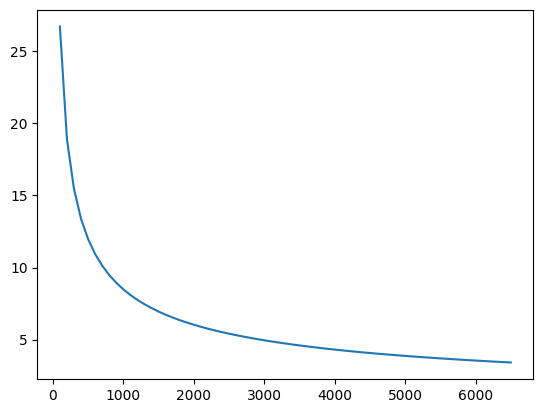

In [ ]:
# Listas para armazenar o histórico da performance
steps= []
results = []

# Retorna um generator de dicionário. As chaves são Step e o nome da métrica
# Exemplo: {"Step": 1, "RMSE": 1.2}, {"Step": 2, "RMSE": 1.1}
progressive_validation = evaluate.iter_progressive_val_score(
    dataset=stream.iter_pandas(X, y),
    model=HoeffdingTreeRegressor(),
    metric=metrics.RMSE(),
    step=100
)

for val in progressive_validation: # Usando o generator
    steps.append(val.get("Step"))
    results.append(val.get("RMSE").get())

plt.plot(steps, results);

### 2.1.2 O método `draw`: visualizar a árvore

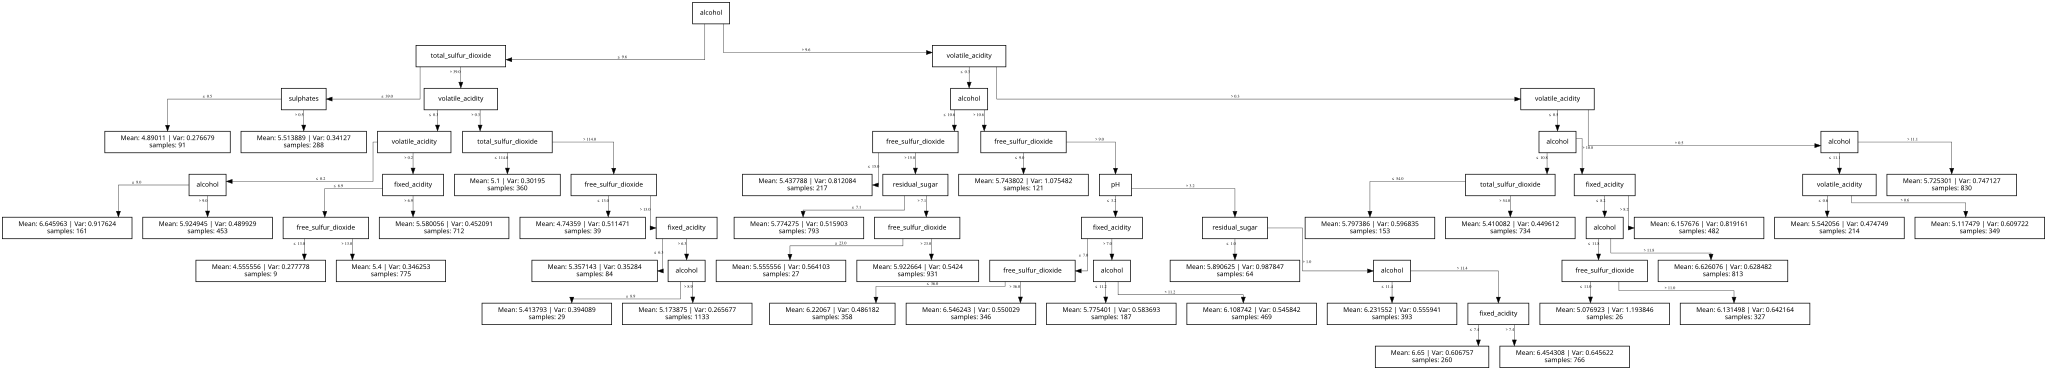

In [ ]:
tree.draw()

## 2.2 Treinar modelo simples de classificação

- *Usando o código desenvolvido em aula, adapte o laço de treino e dados no módulo river para os dados do molusco abalone para treinar um sistema de classificação com árvore de Hoeffding.*

In [ ]:
from river.tree import HoeffdingTreeClassifier

In [ ]:
tree = HoeffdingTreeClassifier() # Versão da Hoeffding Tree para tarefas de regressão
acc = metrics.Accuracy()

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
abalone = fetch_ucirepo(id=1)

# data (as pandas dataframes)
X = abalone.data.features
y = abalone.data.targets

# metadata
print(abalone.metadata)

# variable information
print(abalone.variables)

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

In [ ]:
# Convertendo 'Rings' para o tipo string para classificação
y['Rings'] = y['Rings'].astype(str)

/tmp/ipython-input-4118383507.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y['Rings'] = y['Rings'].astype(str)


In [ ]:
evaluate.progressive_val_score(
    dataset=stream.iter_pandas(X, y['Rings']), # Aqui a argumento precisa ser um Dataset da river,
                                               # Para isso o dataset precisa ser encapsulado
                                               # como foi feito nos casos anteriores
    model=tree,
    metric=acc,
    print_every=500, # Alterado por conta do tamanho do data set
    show_time=True,
    show_memory=True,
)

[500] Accuracy: 22.17% – 00:00:00 – 686.13 KiB
[1,000] Accuracy: 21.88% – 00:00:01 – 686.13 KiB
[1,500] Accuracy: 22.37% – 00:00:02 – 686.13 KiB
[2,000] Accuracy: 22.87% – 00:00:02 – 686.13 KiB
[2,500] Accuracy: 22.48% – 00:00:03 – 686.13 KiB
[3,000] Accuracy: 22.99% – 00:00:03 – 686.13 KiB
[3,500] Accuracy: 22.88% – 00:00:04 – 686.13 KiB
[4,000] Accuracy: 23.15% – 00:00:04 – 686.13 KiB
[4,177] Accuracy: 23.25% – 00:00:04 – 686.13 KiB


Accuracy: 23.25%

- *Crie uma coluna categórica usando o número de aneis (“rings”) dividindo em três categorias como sendo pertencente ao primeiro quartil, os dois intermediários ou ao quarto quartil. Use a função OneHotEncoding para criar as categorias, se achar conveniente.*

In [ ]:
# Calculado os quartis da coluna de 'Rings'
quartiles = y['Rings'].astype(int).quantile([0.25, 0.75])
q1 = quartiles[0.25]
q3 = quartiles[0.75]

# Definindo a função para a categorização de 'Rings'
def categorize_rings(rings):
    rings = int(rings) # Garantindo que 'Rings' seja inteiro
    if rings <= q1:
        return 'primeiro_quartil'
    elif rings > q1 and rings <= q3:
        return 'quartis_intermediarios'
    else:
        return 'quarto_quartil'

# Aplicando a função para a criação da nova coluna categorica 'Rings_category'
y.loc[:, 'Rings_category'] = y['Rings'].apply(categorize_rings)

y.head()

,Rings,Rings_category
0,15,quarto_quartil
1,7,primeiro_quartil
2,9,quartis_intermediarios
3,10,quartis_intermediarios
4,7,primeiro_quartil


# 3. Treinamento com tratamento de dados (Pipeline)